# 日本储能：并网与区域可行性 v2.3

A官方资料、B计算、C假设分别保留。2MW/8.14MWh，278天历史年化不是长期预测。运行目录须为模块根；Python需要NumPy、SciPy、PyMuPDF、Matplotlib，Node24。计算输出写入源码树之外的独立runtime，原始资料不改写。


## 原始证据与保护资产


In [1]:
from pathlib import Path
import os,json,hashlib,subprocess,uuid,sys,math
import numpy as np
import pymupdf as fitz
ROOT=Path.cwd().resolve()
assert (ROOT/'research/feasibility/sources.json').exists()
read=lambda p:json.loads((ROOT/p).read_text(encoding='utf8'))
sha=lambda p:hashlib.sha256(p.read_bytes()).hexdigest()
S=read('research/feasibility/sources.json');source={s['id']:s for s in S}
baseline=read('research/feasibility/baseline.json')
for p,v in baseline['protected_files'].items():assert sha(ROOT/p)==v,p
for s in S:
 if s['status']=='downloaded':assert sha(ROOT/s['raw_file'])==s['sha256'],s['id']
# Runtime is a sibling directory, outside this source tree and any frozen package.
runtime=Path(os.environ.get('JAPAN_BESS_NOTEBOOK_RUNTIME',str(ROOT.parent/'bess-notebook-runtime'))).resolve()
assert not runtime.is_relative_to(ROOT)
SCRATCH=runtime/('v23-'+uuid.uuid4().hex[:10]);SCRATCH.mkdir(parents=True)
OUT=SCRATCH/'research';OUT.mkdir();sys.path.insert(0,str(ROOT/'scripts'))
def run(command,timeout=900):
 p=subprocess.run(command,cwd=ROOT,text=True,encoding='utf8',capture_output=True,timeout=timeout)
 assert p.returncode==0,(command,p.stdout[-1000:],p.stderr[-1000:])
 print(p.stdout[-500:]);return p
def check_tree(a,b):
 if isinstance(a,dict):
  assert set(a)==set(b)
  for k,v in a.items():check_tree(v,b[k])
 elif isinstance(a,list):
  assert len(a)==len(b)
  if a and all(isinstance(x,(int,float)) and not isinstance(x,bool) for x in a):
   np.testing.assert_allclose(a,b,rtol=1e-9,atol=1e-7)
  else:
   for x,y in zip(a,b):check_tree(x,y)
 elif isinstance(a,(int,float)) and not isinstance(a,bool):assert math.isclose(a,b,rel_tol=1e-9,abs_tol=1e-7),(a,b)
 else:assert a==b,(a,b)
def payload(dispatch):
 import prepare_feasibility_assumptions as fa,prepare_feasibility_grid as fg
 fa.prepare(OUT);fg.prepare(OUT)
 check_tree(json.loads((OUT/'assumptions.json').read_text(encoding='utf8')),read('research/feasibility/assumptions.json'))
 run(['node','scripts/prepare_feasibility_payload.mjs','--output-directory',str(OUT),'--dispatch-directory',str(dispatch),'--site-directory','none'])
 return json.loads((OUT/'economics-output.json').read_text(encoding='utf8'))
def graph(title,series,labels,ylabel,filename):
 import matplotlib;matplotlib.use('Agg')
 import matplotlib.pyplot as plt
 from matplotlib.font_manager import FontProperties
 font=FontProperties(fname='C:/Windows/Fonts/msyh.ttc')
 fig,ax=plt.subplots(figsize=(8,3.6));x=np.arange(len(labels))
 for name,values in series:ax.plot(x,values,marker='o',label=name)
 ax.set_xticks(x);ax.set_xticklabels(labels,fontproperties=font,fontsize=8);ax.set_title(title,fontproperties=font);ax.set_ylabel(ylabel,fontproperties=font)
 ax.axhline(0,color='#718096',linewidth=.6);ax.grid(alpha=.15);ax.legend(prop=font,loc='upper left',bbox_to_anchor=(0,-.15),frameon=False)
 fig.tight_layout();p=SCRATCH/filename;fig.savefig(p,dpi=150,bbox_inches='tight');plt.close(fig)
 GRAPHFILES.append(p)
 try:
  from IPython.display import display,Image
  display(Image(filename=str(p)))
 except ImportError:print('Rendered',p.name)
print('19 official records; 16 raw downloads; 215 protected assets verified; scratch',SCRATCH.name)
GRAPHFILES=[]


19 official records; 16 raw downloads; 215 protected assets verified; scratch v23-ecb7b6aade


## 同日期同单位区域表与缺失值


In [2]:
import prepare_feasibility_grid as fg
fg.prepare(OUT);G=json.loads((OUT/'grid-normalized.json').read_text(encoding='utf8'));check_tree(G,read('research/feasibility/grid-normalized.json'))
doc=fitz.open(ROOT/source['meti-grid-2026']['raw_file']);assert '19,114' in doc[2].get_text() and '3,527' in doc[2].get_text()
for r in G['regions']:
 assert r['snapshot_date']=='2026-03-31' and r['normalized_unit']=='MW'
 for k in ['site_connection_capacity_mw','site_connection_cost_jpy','region_average_lead_time_years','site_voltage','site_approval']:assert r[k] is None
 print(r['title'],r['review_application_mw'],r['contract_application_mw'],'MW; site conditions unknown; development sample date',r['development_sample']['as_of_jst'])
print('Raw PDF same-date high-voltage table reproduced; application stages not added; regional missing data remain null.')


Normalized five comparable regional application observations; no site approval or hidden score
中部 17360 4410 MW; site conditions unknown; development sample date 2026-10-07
东京 36110 6730 MW; site conditions unknown; development sample date 2026-10-07
关西 10940 2920 MW; site conditions unknown; development sample date 2026-10-07
九州 13480 6580 MW; site conditions unknown; development sample date 2026-10-07
东北 75440 5770 MW; site conditions unknown; development sample date 2026-10-07
Raw PDF same-date high-voltage table reproduced; application stages not added; regional missing data remain null.


## 统一C压力、寿命和项目DCF


In [3]:
E=payload(ROOT/'research/feasibility/dispatch-cases');F=json.loads((OUT/'grid-output.json').read_text(encoding='utf8'));check_tree(F,read('research/feasibility/grid-output.json'))
assert len(F['comparisons'])==60
for x in F['comparisons']:
 assert x['gridScenario']['identity']=='C'
 for y in x['lifetime']['years']:assert y['trajectoryScale']<=1
print('60 grid pressure/lifetime/DCF comparisons recomputed. Uniform20% availability and4-year delay are C, not inferred from official queue sizes.')


Prepared explicit projectC assumptions and 9 separate primary reference observations
Normalized five comparable regional application observations; no site approval or hidden score
:137252495.7971161,"breakEvenAnnualOperatingContribution":87405036.80852945},{"cost":"high","initialInvestment":839000000.0000001,"annualOperatingContribution":27567702.56776736,"year1FreeCashflow":9372702.56776736,"npv":-1003362488.2056773,"projectIRR":{"value":null,"roots":[],"status":"outside_search_range"},"payback":null,"lifetimeProfit":-1398952984.864988,"lifetimeFreeCashflow":-559952984.8649879,"breakEvenCapex":91884526.65488683,"breakEvenAnnualOperatingContribution":133605837.57418701}]

60 grid pressure/lifetime/DCF comparisons recomputed. Uniform20% availability and4-year delay are C, not inferred from official queue sizes.


## 并列图表与最终SHA


Rendered grid-pressure.png
REPLAY_PASSED: official grid originals -> date/unit/grain normalization -> development sample kept separate -> missing preserved -> common C stress -> finance -> chart contract. No hidden region score.


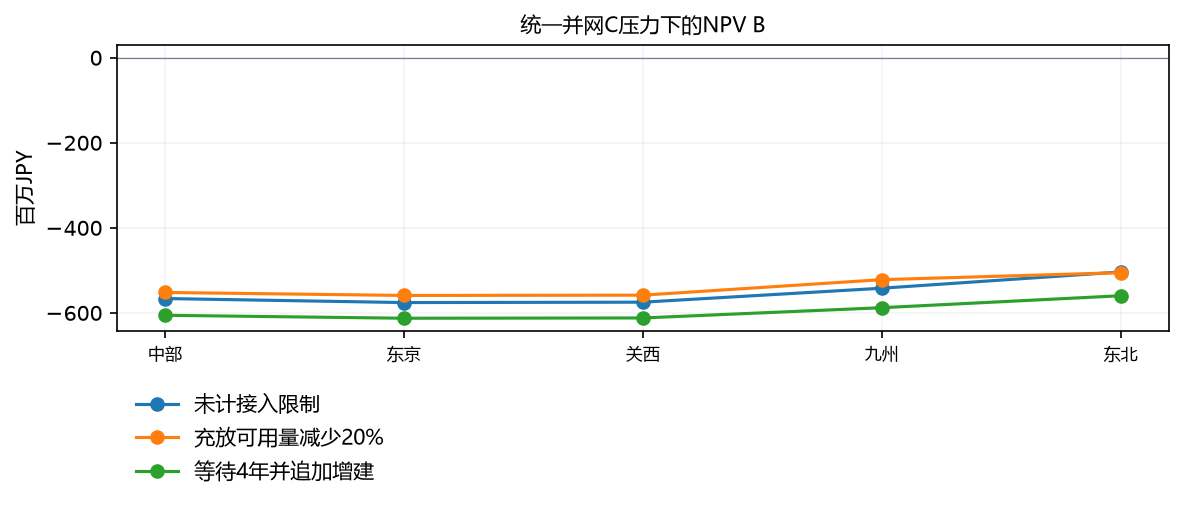

In [4]:
rows=[x for x in F['comparisons'] if x['scenario']=='base']
A=read('research/feasibility/assumptions.json');regions=['chubu','tokyo','kansai','kyushu','tohoku'];names=[next(r['title'] for r in G['regions'] if r['region']==id) for id in regions]
series=[(g['title'],[next(x['npv']/1e6 for x in rows if x['region']==r and x['gridID']==id) for r in regions]) for id,g in A['grid_scenarios'].items()]
graph('统一并网C压力下的NPV B',series,names,'百万JPY','grid-pressure.png')
contract=next(f for f in read('research/feasibility/report-data.json')['figures'] if f['id']=='grid-pressure')
for (name,values),s in zip(series,contract['series']):assert name==s['name'];np.testing.assert_allclose(values,s['values'])
for p,v in baseline['protected_files'].items():assert sha(ROOT/p)==v
print('REPLAY_PASSED: official grid originals -> date/unit/grain normalization -> development sample kept separate -> missing preserved -> common C stress -> finance -> chart contract. No hidden region score.')
